In [113]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, accuracy_score, precision_score, 
    recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
)

plt.rcParams['figure.dpi'] = 300
sns.set_theme(style="whitegrid")
print("✅ Langkah 1 Berhasil: Library siap!")

✅ Langkah 1 Berhasil: Library siap!


In [114]:

df = pd.read_csv('SATUSEHAT_clean_balanced.csv', sep=';')

# 2. Ambil kolom teks ('content') dan label ('labelScoreBase')
X = df['content']          # Kolom teks ulasan
y = df['labelScoreBase']   # Kolom label/sentimen (sesuaikan jika mau pakai kolom 'score')

# 3. Split Data 80% Training & 20% Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


print(f"Data Latih: {len(X_train)} | Data Uji: {len(X_test)}")

Data Latih: 3195 | Data Uji: 799


In [115]:
# Ubah ngram_setting untuk Ablation Study:
# Run 1 = (1, 1) | Run 2 = (2, 2) | Run 3 = (1, 2)
RUN_NAME = "Run 1 (unigram)"
ngram_setting = (1, 2)

vectorizer = TfidfVectorizer(ngram_range=ngram_setting, min_df=3)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"✅ TF-IDF Selesai untuk {RUN_NAME}")
print(f"Total Fitur Kata: {X_train_tfidf.shape[1]} kolom")

✅ TF-IDF Selesai untuk Run 1 (unigram)
Total Fitur Kata: 3333 kolom


In [116]:
param_grid = {'C': [0.01, 0.1, 1.0, 10.0]}
lr_model = LogisticRegression(max_iter=1000, random_state=42)

grid_search = GridSearchCV(
    estimator=lr_model,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train_tfidf, y_train)

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test_tfidf)
y_prob = best_model.predict_proba(X_test_tfidf)[:, 1]

print(f"✅ Parameter C Terbaik: {grid_search.best_params_['C']}\n")


cv_results = pd.DataFrame(grid_search.cv_results_)
ringkasan_tuning = cv_results[['param_C', 'mean_test_score', 'std_test_score', 'rank_test_score']]
ringkasan_tuning.columns = ['Nilai C', 'Rata-rata Akurasi (CV)', 'Standar Deviasi', 'Peringkat']
ringkasan_tuning = ringkasan_tuning.sort_values(by='Peringkat').reset_index(drop=True)

print("=== HASIL RINCIAN HYPERPARAMETER TUNING (GRIDSEARCHCV) ===")
print(ringkasan_tuning.to_string(index=False))

✅ Parameter C Terbaik: 1.0

=== HASIL RINCIAN HYPERPARAMETER TUNING (GRIDSEARCHCV) ===
 Nilai C  Rata-rata Akurasi (CV)  Standar Deviasi  Peringkat
    1.00                0.819092         0.011819          1
    0.10                0.808764         0.016574          2
   10.00                0.804382         0.005599          3
    0.01                0.797183         0.023225          4


In [117]:

labels = np.unique(y_test)


pos_label_val = labels[1] if len(labels) == 2 else labels[0]
for lbl in labels:
    if str(lbl).lower() in ['positif', 'positive', '1', '1.0']:
        pos_label_val = lbl
        break

# Konversi target uji ke biner (0/1) khusus perhitungan ROC AUC
y_test_binary = (y_test == pos_label_val).astype(int)

# 2. Cetak Hasil Evaluasi
print(f"==========================================")
print(f"   HASIL EVALUASI: {RUN_NAME}")
print(f"==========================================")
print(f"Label Positif Terdeteksi : '{pos_label_val}'")
print(f"Accuracy  : {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Precision : {precision_score(y_test, y_pred, pos_label=pos_label_val)*100:.2f}%")
print(f"Recall    : {recall_score(y_test, y_pred, pos_label=pos_label_val)*100:.2f}%")
print(f"F1-Score  : {f1_score(y_test, y_pred, pos_label=pos_label_val)*100:.2f}%")
print(f"AUC Score : {roc_auc_score(y_test_binary, y_prob):.4f}\n")

print("Detail Classification Report (4 Desimal):")
print(classification_report(y_test, y_pred, digits=4))

   HASIL EVALUASI: Run 1 (unigram)
Label Positif Terdeteksi : 'Positive'
Accuracy  : 83.98%
Precision : 85.75%
Recall    : 81.45%
F1-Score  : 83.55%
AUC Score : 0.9009

Detail Classification Report (4 Desimal):
              precision    recall  f1-score   support

    Negative     0.8238    0.8650    0.8439       400
    Positive     0.8575    0.8145    0.8355       399

    accuracy                         0.8398       799
   macro avg     0.8407    0.8398    0.8397       799
weighted avg     0.8406    0.8398    0.8397       799



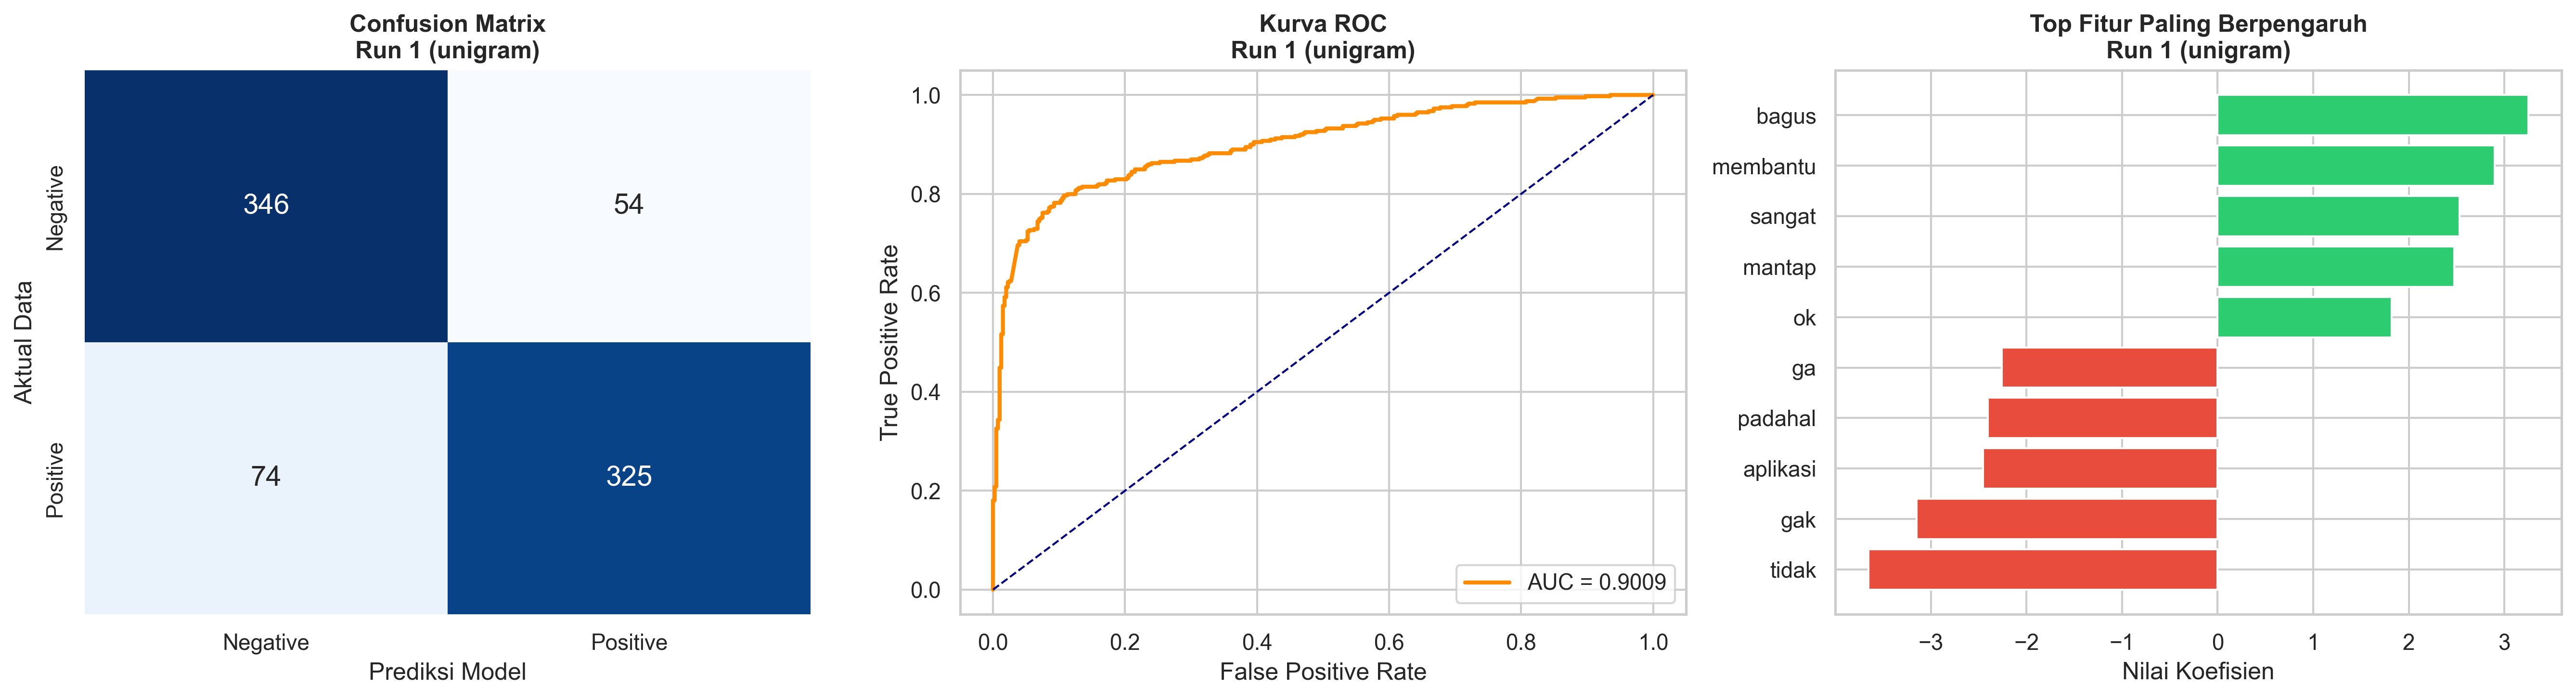

In [118]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=np.unique(y), yticklabels=np.unique(y), annot_kws={"size": 14})
axes[0].set_title(f'Confusion Matrix\n{RUN_NAME}', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Prediksi Model')
axes[0].set_ylabel('Aktual Data')

# 2. Kurva ROC
fpr, tpr, _ = roc_curve(y_test, y_prob, pos_label=pos_label_val)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc_score(y_test, y_prob):.4f}')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--')
axes[1].set_title(f'Kurva ROC\n{RUN_NAME}', fontsize=12, fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc="lower right")

# 3. Top Kata Berpengaruh
feature_names = np.array(vectorizer.get_feature_names_out())
coef = best_model.coef_[0]
top_positive = np.argsort(coef)[-5:]
top_negative = np.argsort(coef)[:5]
top_indices = np.hstack([top_negative, top_positive])

colors = ['#e74c3c' if c < 0 else '#2ecc71' for c in coef[top_indices]]
axes[2].barh(feature_names[top_indices], coef[top_indices], color=colors)
axes[2].set_title(f'Top Fitur Paling Berpengaruh\n{RUN_NAME}', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Nilai Koefisien')

plt.tight_layout()
plt.show()

In [119]:
# Pembulatan 2 desimal dulu baru dikurang
train_acc = round(best_model.score(X_train_tfidf, y_train) * 100, 2)
test_acc = round(accuracy_score(y_test, y_pred) * 100, 2)
gap_acc = train_acc - test_acc

# Tampilkan analisis evaluasi & generalisasi
print(f"Akurasi Data Latih (Train) : {train_acc:.2f}%")
print(f"Akurasi Data Uji (Test)   : {test_acc:.2f}%")
print(f"Gap / Selisih             : {gap_acc:.2f}%")

if gap_acc <= 10:
    print("Status Model               : Good Fit (Bebas Overfitting)")
else:
    print("Status Model               : Terindikasi Overfitting")

Akurasi Data Latih (Train) : 89.08%
Akurasi Data Uji (Test)   : 83.98%
Gap / Selisih             : 5.10%
Status Model               : Good Fit (Bebas Overfitting)
